In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/winequality-red.csv", sep=";")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 1599
Columns: 1


In [2]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

First 5 rows:


,"fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality"
0,"7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0...."
1,"7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.2,0...."
2,"7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0..."
3,"11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,..."
4,"7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0...."



Column names:
['fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 1 columns):
 #   Column                                                                                                                                             Non-Null Count  Dtype
---  ------                                                                                                                                             --------------  -----
 0   fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality  1599 non-null   str  
dtypes: str(1)
memory usage: 12.6 KB


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality    0
dtype: int64

Total missing values:
0


In [4]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 240


In [5]:
print("Exact column names:")
for column in df.columns:
    print(repr(column))

Exact column names:
'fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality'


In [6]:
print("Exact column names:")
for column in df.columns:
    print(repr(column))

Exact column names:
'fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality'


In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/winequality-red.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Rows: 1599
Columns: 12

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [8]:
print("Wine Quality Distribution:")
print(df["quality"].value_counts().sort_index())

print("\nQuality Statistics:")
print(df["quality"].describe())

Wine Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Quality Statistics:
count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64


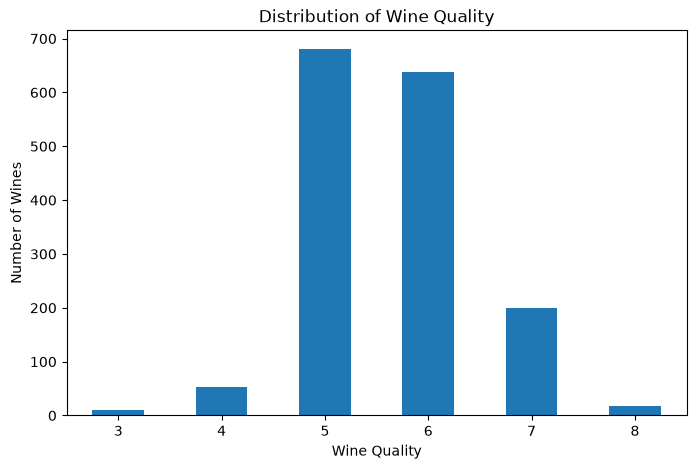

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df["quality"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")
plt.xticks(rotation=0)

plt.show()

In [10]:
# Calculate correlations with wine quality

quality_correlations = (
    df.corr(numeric_only=True)["quality"]
    .sort_values(ascending=False)
)

print("Correlation with Wine Quality:")
print(quality_correlations)

Correlation with Wine Quality:
quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


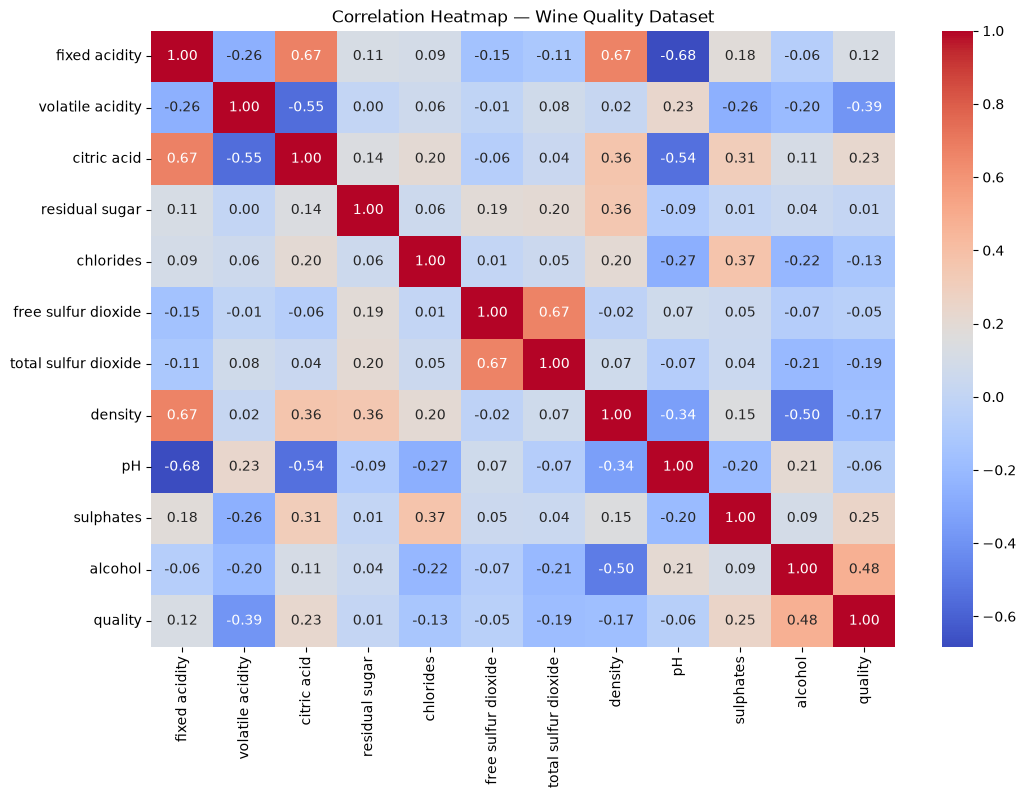

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap — Wine Quality Dataset")
plt.show()

In [12]:
# Separate features and target

X = df.drop("quality", axis=1)
y = df["quality"]

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features (X):
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Target (y):
quality

X shape: (1599, 11)
y shape: (1599,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training data:
X_train: (1279, 11)
y_train: (1279,)

Testing data:
X_test: (320, 11)
y_test: (320,)


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

Feature scaling completed successfully!
X_train_scaled shape: (1279, 11)
X_test_scaled shape: (320, 11)


In [15]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [16]:
# Make predictions
y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

print("\nFirst 20 predicted quality scores:")
print(y_pred[:20])

Predictions generated successfully!
Number of predictions: 320

First 20 predicted quality scores:
[5 5 5 5 6 5 5 5 6 6 7 5 6 5 6 6 5 6 7 5]


In [17]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("========== MODEL EVALUATION ==========")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

========== MODEL EVALUATION ==========
Accuracy: 66.56 %

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.71      0.73      0.72       130
           6       0.62      0.72      0.67       132
           7       0.70      0.55      0.61        42
           8       0.00      0.00      0.00         5

    accuracy                           0.67       320
   macro avg       0.34      0.33      0.33       320
weighted avg       0.64      0.67      0.65       320



c:\Users\amanm\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\amanm\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\amanm\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

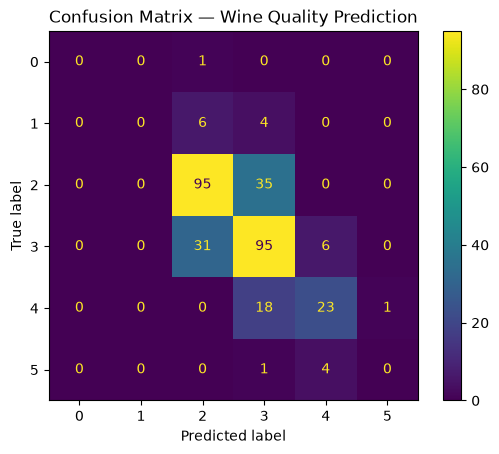

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.title("Confusion Matrix — Wine Quality Prediction")
plt.show()

In [19]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,Feature,Importance
10,alcohol,0.150554
9,sulphates,0.114641
6,total sulfur dioxide,0.104208
1,volatile acidity,0.095587
7,density,0.093198
4,chlorides,0.080521
0,fixed acidity,0.075443
8,pH,0.075061
2,citric acid,0.071710
3,residual sugar,0.070996


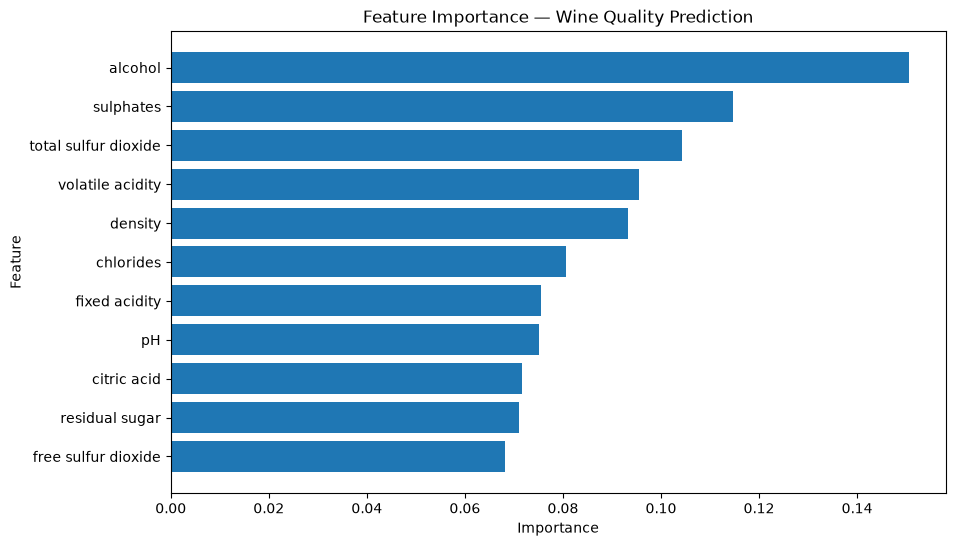

In [20]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance — Wine Quality Prediction")

plt.gca().invert_yaxis()
plt.show()

In [21]:
import os

prediction_results = pd.DataFrame({
    "Actual Quality": y_test.values,
    "Predicted Quality": y_pred
})

prediction_results["Correct Prediction"] = (
    prediction_results["Actual Quality"]
    == prediction_results["Predicted Quality"]
)

output_file = "../output/wine_quality_predictions.csv"

prediction_results.to_csv(output_file, index=False)

print("Prediction results saved successfully!")
print("File:", output_file)
print("File exists:", os.path.exists(output_file))

display(prediction_results.head(10))

Prediction results saved successfully!
File: ../output/wine_quality_predictions.csv
File exists: True


,Actual Quality,Predicted Quality,Correct Prediction
0,6,5,False
1,5,5,True
2,6,5,False
3,5,5,True
4,6,6,True
5,5,5,True
6,5,5,True
7,5,5,True
8,5,6,False
9,6,6,True


In [22]:
print("========== WINE QUALITY PREDICTION SUMMARY ==========")

print("Dataset Size:", df.shape)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModel: Random Forest Classifier")

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nTarget Variable: quality")

print("\nNumber of Features:", X.shape[1])

print("\nFeatures Used:")
print(X.columns.tolist())

print("\nMost Important Features:")
display(feature_importance.head(5))

========== WINE QUALITY PREDICTION SUMMARY ==========
Dataset Size: (1599, 12)
Training Records: 1279
Testing Records: 320

Model: Random Forest Classifier

Model Accuracy: 66.56 %

Target Variable: quality

Number of Features: 11

Features Used:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Most Important Features:


,Feature,Importance
10,alcohol,0.150554
9,sulphates,0.114641
6,total sulfur dioxide,0.104208
1,volatile acidity,0.095587
7,density,0.093198


# Final Observations and Conclusion

## Observations

1. The dataset contains 1,599 red wine records with 11 chemical properties and one target variable, `quality`.
2. The wine quality distribution shows that the dataset contains multiple quality classes.
3. The chemical properties were used as input features to predict wine quality.
4. The dataset was divided into 80% training data and 20% testing data.
5. StandardScaler was used to scale the numerical features before model training.
6. A Random Forest Classifier was trained to predict wine quality.
7. Model performance was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.
8. Feature importance analysis was used to identify the chemical properties that contributed most to the model's predictions.

## Conclusion

The Random Forest Classifier provides a machine-learning approach for predicting red wine quality from its chemical properties. The model's performance was evaluated using the test dataset, and feature importance analysis provided insights into the chemical characteristics that were most useful for prediction.

The model can be further improved in future work by applying hyperparameter tuning, testing additional machine-learning algorithms, handling class imbalance, and performing more advanced feature engineering.